# 독성 모델링: 계열 분리 검증부터 제출 CSV까지

2026-10-02 · 1반 3조. 어제 만든 Morgan+8 EDA 노트북, 최신 발표자료, 관련 논문과 과제 PDF를 참고했다.

**결과를 먼저 읽기:** 모델 비교 → 잠근 모델/임계값 → 분자 골격 holdout → 제출값 검증. 아래 셀에는 실제 실행 결과를 저장한다. `RETRAIN=False`이면 이미 생성한 모델/평가를 읽고 재검증한다. `True`로 바꾸면 학습 및 결과 생성을 다시 수행한다.

원본 예측 양식의 927개 `1`은 예시값이다. `01_원본자료/predict_output_홍길동.csv`는 보존하고 `06_모델링/predict_output_모델예측.csv`에 같은 `SMILES,output` 구조로 저장했다.

**label 주의:** 현재 학습은 1=독성/0=비독성. 과제 PDF 13·15쪽의 제출 규약은 1=비독성/0=독성이다. 제출값은 `1 - prediction_toxic`이다. 원본 CSV/기존 EDA/PPT는 변경하지 않는다.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, inspect, tempfile
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir())/'toxicity-matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, *[p for p in cwd.iterdir() if p.is_dir()]]
ROOT = next(p for p in candidates if (p/'02_데이터/train.csv').exists())
DEST = ROOT/'06_모델링'
sys.path.insert(0, str(ROOT/'03_분석/스크립트'))
import train_toxicity_models as modeling
RETRAIN = False
if RETRAIN:
    modeling.main()
    modeling.run_ablation()
summary = json.loads((DEST/'modeling_summary.json').read_text())
print('프로젝트:', ROOT)
print('실행 버전:', summary['versions'])
modeling.self_check()

프로젝트: /Users/seohyeokin/workspace/skala-RAGPipline/미니프로젝트
실행 버전: {'python': '3.11.15', 'numpy': '2.4.6', 'pandas': '3.0.5', 'sklearn': '1.9.0', 'rdkit': '2025.09.6', 'lightgbm': '4.7.0', 'joblib': '1.5.3'}
PASS: label inversion, CSV preservation, metrics and stereo parsing


## 1. 데이터·제출 계약과 원본 보존

8349행을 전부 유지했다. 학습 파일과 반전 전 백업의 label을 대조하고, 예측 입력과 예시 양식의 SMILES 순서를 대조한다. 모든 기존 입력 파일의 SHA-256이 학습 전과 같은지 다시 확인한다.

In [2]:
train = pd.read_csv(ROOT/'02_데이터/train.csv', usecols=['SMILES','label'])
original = pd.read_csv(ROOT/'01_원본자료/train_original_labels.csv.bak', usecols=['SMILES','label'])
template = pd.read_csv(ROOT/'01_원본자료/predict_output_홍길동.csv')
predict_input = pd.read_csv(ROOT/'01_원본자료/predict_input.csv', usecols=['SMILES'])
assert train.SMILES.equals(original.SMILES)
assert np.array_equal(train.label, 1-original.label)
assert template.SMILES.equals(predict_input.SMILES)
for relative_path, expected in summary['protected_source_hashes'].items():
    assert hashlib.sha256((ROOT/relative_path).read_bytes()).hexdigest() == expected
print('PASS: 기존 데이터·예측양식·EDA 노트북 원본 보존')
display(pd.DataFrame({'학습_독성label': train.label.value_counts().sort_index(),
                      '원본_비독성label': original.label.value_counts().sort_index()}))

PASS: 기존 데이터·예측양식·EDA 노트북 원본 보존


,학습_독성label,원본_비독성label
label,,
0,4542,3807
1,3807,4542


## 2. 학습·예측에서 같은 전처리

기존 `run_stereo_eda.describe`를 재사용한다. Morgan은 radius2/1024비트/includeChirality=True이다. 학습8349행 전체를 재계산해 어제 최종 파일의 3035개 숫자 변수와 일치함을 확인했다. 예측927행에도 같은 함수와 고정 사전을 적용한다.

최종 후보는 **국소 입체5개를 제외한 3030개 변수**(Morgan+FCFP+상수49개 제거 PTFP+물성4개+전역입체3개)를 사용한다. 기존 8개 가운데 국소5개는 전체 label 충돌에서 골라서, +8 성능은 탐색으로만 남긴다. label을 본 특징 선정의 영향을 새로운 독립 검증이라고 주장하지 않는다.

In [3]:
print(inspect.getsource(modeling.transform))
cache = np.load(DEST/'feature_cache.npz')
assert cache['X'].shape == (8349,3035) and cache['Q'].shape == (927,3035)
assert summary['feature_recalculation_matches_all_training_rows']
print('PASS: 전체 학습/예측 특징 유한값 및 EDA 재계산 대조 완료')

def transform(frame, columns, local_dictionary):
    """Use the existing EDA parser for both training and prediction."""
    records = [history.describe(s, with_morgan=False) for s in frame.SMILES]
    fingerprints = np.empty((len(frame), 1024), dtype=np.int8)
    for i, record in enumerate(records):
        DataStructs.ConvertToNumpyArray(history.GEN.GetFingerprint(record['mol']), fingerprints[i])
    result = frame.drop(columns=['label'], errors='ignore').copy()
    result[[f'ecfp_{i}' for i in range(1024)]] = fingerprints
    derived = {name: [r['scalar'][name] for r in records] for name in BASE}
    derived.update({name: [r['local'][key] for r in records] for name, key in local_dictionary.items()})
    result = pd.concat([result, pd.DataFrame(derived, index=result.index)], axis=1)
    groups = np.array([MurckoScaffold.MurckoScaffoldSmiles(mol=r['mol'], includeChirality=False)
                       or 'ACYCLIC' for r in records])
    connectivity = np.array([r['canonical_connectivi

## 3. 분자 골격 그룹 분리

Bemis–Murcko scaffold의 입체표시는 그룹 계산에서 무시한다. 같은 골격과 연결구조가 양쪽에 들어가지 않도록 한다. 고리가 없는 분자는 하나의 ACYCLIC 그룹이다.

seed42의 5분할 첫 fold를 holdout으로 잠그고, 나머지 개발 데이터에서 4분할 교차검증한다. scaling은 Pipeline 안에서 각 학습 fold로만 맞춘다. 골격이 다르더라도 유사한 분자가 있을 수 있으므로 모든 화학적 유사성을 제거한 평가라는 뜻은 아니다.

In [4]:
splits = pd.read_csv(DEST/'split_manifest.csv').fillna({'scaffold':'ACYCLIC'})
dev = splits.split.eq('development')
holdout = ~dev
assert not set(splits.loc[dev,'scaffold']) & set(splits.loc[holdout,'scaffold'])
assert not set(splits.loc[dev,'connectivity']) & set(splits.loc[holdout,'connectivity'])
for fold in range(4):
    valid = dev & splits.dev_fold.eq(fold)
    fit = dev & ~splits.dev_fold.eq(fold)
    assert not set(splits.loc[valid,'scaffold']) & set(splits.loc[fit,'scaffold'])
    assert not set(splits.loc[valid,'connectivity']) & set(splits.loc[fit,'connectivity'])
display(splits.groupby('split').agg(rows=('label_toxic','size'),
    toxic_rate=('label_toxic','mean'),scaffolds=('scaffold','nunique')))
print('PASS: 최종 holdout 및 CV의 골격·연결구조 중복 0건')

,rows,toxic_rate,scaffolds
split,,,
development,6673,0.456017,3322
holdout,1676,0.455847,838


PASS: 최종 holdout 및 CV의 골격·연결구조 중복 0건


## 4. 실제 모델 비교

다수 클래스 기준선, 기존 ECFP 로지스틱, Morgan 로지스틱, RandomForest, ExtraTrees, LightGBM(31/15 leaves), RBF-SVM, 탐색용 +8 LightGBM을 비교했다. 학습 시간과 fold 변동을 같이 기록한다.

OOF ROC-AUC로 최종 후보를 선택한다. 상위3개의 단순 평균은 AUC가 최고 단일 모델보다 0.002 이상 좋아야 채택한다. 이 평균은 논문의 stacking 구조를 그대로 재현한 것이 아니다. 개발 성능은 후보 선택에 사용했으므로 최종 성능과 구별한다.

,model,eligible,feature_count,roc_auc,fold_auc_std,accuracy,f1_toxic,f1_safe,macro_f1,seconds
0,lightgbm_31,True,3030.0,0.844824,0.014260,0.762775,0.730461,0.788171,0.759316,8.254501
1,lightgbm_plus8_exploratory,False,3035.0,0.844824,0.014260,0.762775,0.730461,0.788171,0.759316,9.023876
2,mean_top3,True,NaN,0.842226,NaN,0.756331,0.723469,0.782213,0.752841,0.000000
3,lightgbm_15,True,3030.0,0.835875,0.012566,0.746591,0.712366,0.773537,0.742951,5.030926
4,svm_rbf,True,3030.0,0.827693,0.010289,0.747040,0.717063,0.771274,0.744169,237.288132
5,random_forest,True,3030.0,0.825488,0.006803,0.752435,0.708950,0.784615,0.746783,4.360332
6,extra_trees,True,3030.0,0.819836,0.010276,0.754983,0.715702,0.784727,0.750214,8.298818
7,logistic_morgan_global3,True,3030.0,0.805515,0.003341,0.732954,0.700806,0.758863,0.729835,1.240102
8,logistic_original,True,3027.0,0.805185,0.004551,0.732654,0.699157,0.759439,0.729298,1.280940
9,dummy_majority,True,3030.0,0.499713,0.000000,0.543983,0.000000,0.704649,0.352325,0.091999


,mean,std,min,max
model,,,,
dummy_majority,0.500000,0.000000,0.500000,0.500000
extra_trees,0.820029,0.010276,0.808771,0.833630
lightgbm_15,0.836544,0.012566,0.823189,0.850004
lightgbm_31,0.845241,0.014260,0.827995,0.861474
lightgbm_plus8_exploratory,0.845241,0.014260,0.827995,0.861474
logistic_morgan_global3,0.805489,0.003341,0.802011,0.808411
logistic_original,0.805097,0.004551,0.798691,0.809118
random_forest,0.825556,0.006803,0.816147,0.832013
svm_rbf,0.828127,0.010289,0.818523,0.840144


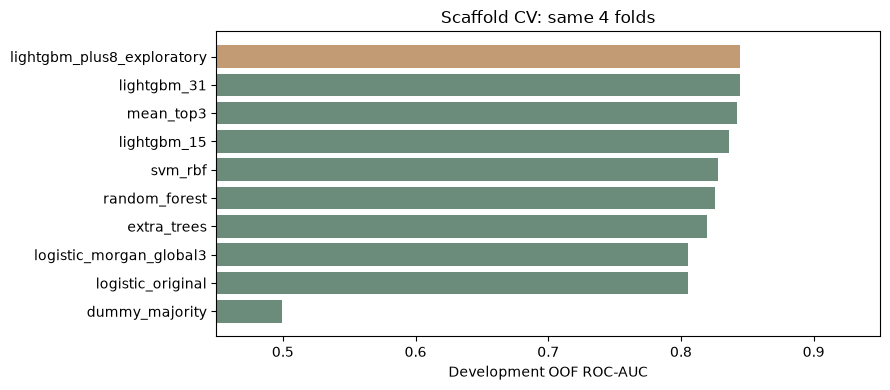

In [5]:
comparison = pd.read_csv(DEST/'model_comparison.csv')
display(comparison.sort_values('roc_auc',ascending=False)[[
    'model','eligible','feature_count','roc_auc','fold_auc_std','accuracy',
    'f1_toxic','f1_safe','macro_f1','seconds']])
folds = pd.read_csv(DEST/'cv_folds.csv')
display(folds.groupby('model').roc_auc.agg(['mean','std','min','max']))
fig, ax = plt.subplots(figsize=(9,4))
ordered = comparison.sort_values('roc_auc')
ax.barh(ordered.model,ordered.roc_auc,color=['#6b8c7a' if x else '#c29b75' for x in ordered.eligible])
ax.set(xlabel='Development OOF ROC-AUC',xlim=(.45,.95),title='Scaffold CV: same 4 folds')
plt.tight_layout(); plt.show()

## 5. 모델과 임계값을 고정

개발 OOF에서 양쪽 클래스의 macro-F1을 최대화하는 threshold를 0.15~0.85 사이 0.005 간격으로 비교했다. 동률이면 0.5에 가까운 값을 택한다. 최종 평가 데이터의 label은 threshold 선택에 사용하지 않는다.

{
  "models": [
    "lightgbm_31"
  ],
  "threshold_toxic": 0.44999999999999996,
  "primary_metric": "OOF ROC-AUC",
  "threshold_metric": "OOF macro-F1",
  "ensemble_minimum_auc_gain": 0.002,
  "development_scores_at_threshold": {
    "roc_auc": 0.8448240961281321,
    "pr_auc_toxic": 0.8277704990255035,
    "pr_auc_safe": 0.8620602299622507,
    "accuracy": 0.763224936310505,
    "precision_toxic": 0.7396003930560104,
    "recall_toxic": 0.7420308905685179,
    "f1_toxic": 0.7408136482939632,
    "precision_safe": 0.7831491712707183,
    "recall_safe": 0.78099173553719,
    "f1_safe": 0.7820689655172414,
    "macro_f1": 0.7614413069056023,
    "specificity_toxic": 0.78099173553719,
    "specificity_safe": 0.7420308905685179,
    "brier": 0.16176929549785246,
    "tn": 2835,
    "fp": 795,
    "fn": 785,
    "tp": 2258
  }
}


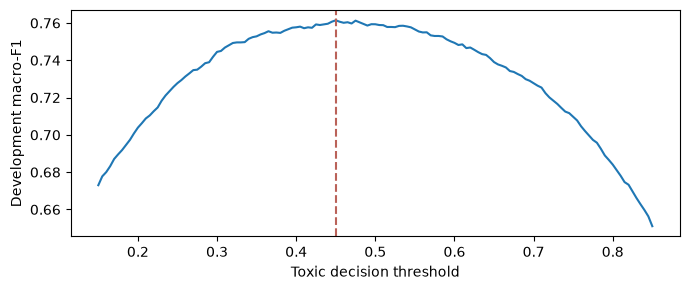

In [6]:
locked = json.loads((DEST/'selection_locked.json').read_text())
print(json.dumps(locked,ensure_ascii=False,indent=2))
curve = pd.read_csv(DEST/'threshold_search.csv')
fig,ax=plt.subplots(figsize=(7,3))
ax.plot(curve.threshold_toxic,curve.oof_macro_f1)
ax.axvline(locked['threshold_toxic'],color='#ba6259',linestyle='--')
ax.set(xlabel='Toxic decision threshold',ylabel='Development macro-F1')
plt.tight_layout(); plt.show()

## 6. 잠근 모델의 최종 골격 holdout 평가

평가용 행을 학습하지 않은 개발 모델로 한 번 평가했다. 그 이후 8349행 전체로 다시 학습한 모델은 제출 추론용이다. 제출 모델이 holdout을 제외하고 학습된 모델이라는 뜻은 아니다.

독성과 비독성의 Precision/Recall/F1을 모두 보여준다. 제출 기준 positive=비독성의 F1은 `f1_safe`이고, 독성 탐지 F1은 `f1_toxic`이다. specificity도 양쪽 기준을 구별한다. 신뢰구간은 holdout 골격 그룹을 300회 bootstrap한 내부 불확실성 추정치다.

,Locked threshold,Threshold 0.5,Majority baseline
roc_auc,0.844755,0.844755,0.500000
pr_auc_toxic,0.824617,0.824617,0.455847
pr_auc_safe,0.857954,0.857954,0.544153
accuracy,0.770286,0.767303,0.544153
precision_toxic,0.764296,0.784195,0.000000
recall_toxic,0.717277,0.675393,0.000000
f1_toxic,0.740041,0.725738,0.000000
precision_safe,0.774765,0.756385,0.544153
recall_safe,0.814693,0.844298,1.000000
f1_safe,0.794228,0.797927,0.704791


Group bootstrap 95% intervals: {'roc_auc_95_percent': [0.8153997187680873, 0.8701384043444165], 'macro_f1_95_percent': [0.7359732518043736, 0.7958882834424468], 'group_bootstrap_repeats': 300}


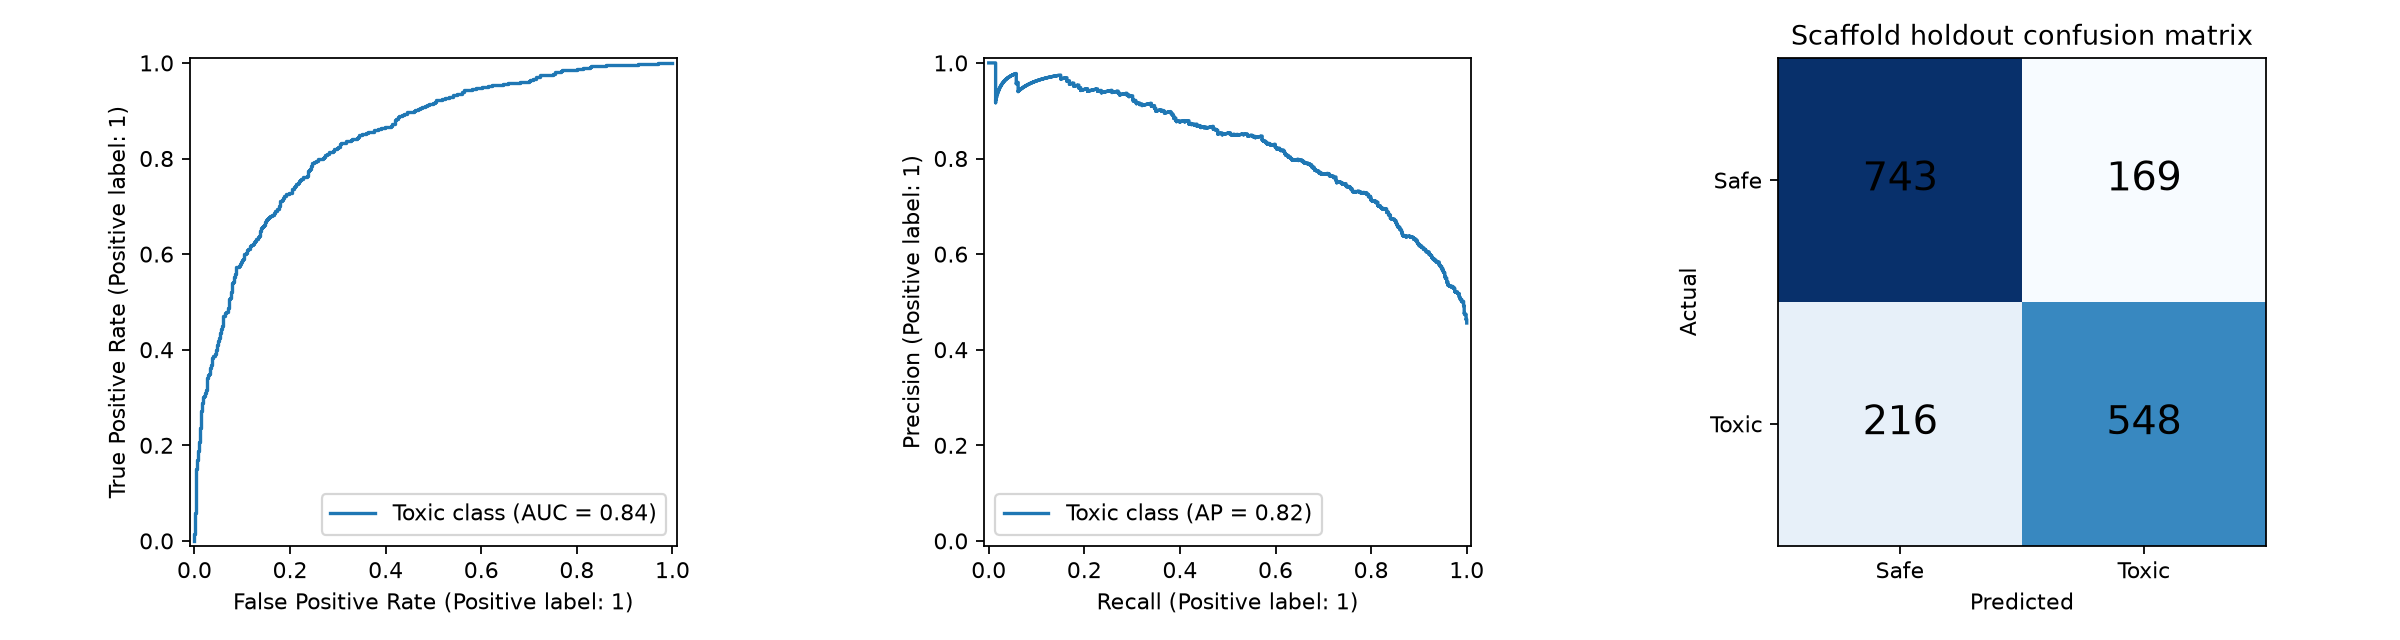

error_kind
false_negative    216
false_positive    169
Name: 행 수, dtype: int64

,slice,n,roc_auc,pr_auc_toxic,pr_auc_safe,accuracy,precision_toxic,recall_toxic,f1_toxic,precision_safe,recall_safe,f1_safe,macro_f1,specificity_toxic,specificity_safe,brier,tn,fp,fn,tp
0,stereo_unassigned,383,0.879685,0.848041,0.907322,0.791123,0.782895,0.716867,0.748428,0.796537,0.847926,0.821429,0.784928,0.847926,0.716867,0.144121,184,33,47,119
1,no_unassigned,1293,0.834049,0.818620,0.838878,0.764114,0.759292,0.717391,0.737747,0.767857,0.804317,0.785664,0.761706,0.804317,0.717391,0.166130,559,136,169,429


,csv_row,SMILES,scaffold,label_toxic,probability_toxic,prediction_toxic,error_kind
350,7503,Cc1c(ccc(F)c1C#N)[C@@H]2CN3CCN(C[C@H]3CO2)C(=O...,O=C(Cc1cnc(-n2cnnn2)nc1)N1CCN2CC(c3ccccc3)OCC2C1,1,0.010298,0,false_negative
282,6051,COc1ccc(cc1)c2oc(C)c(COc3cccc(CN(CC(=O)O)C(=O)...,O=C(NCc1cccc(OCc2coc(-c3ccccc3)n2)c1)Oc1ccccc1,1,0.017599,0,false_negative
372,8144,CC[C@@H](NC(=O)c1cc(C(=O)N2CCC[C@@H]2C)n3CCOCc...,O=C(NCc1ccccc1)c1cc(C(=O)N2CCCC2)n2c1COCC2,1,0.018265,0,false_negative
383,8334,C[C@@H]1O[C@@H](O[C@H]2C[C@@H](O)[C@]3(CO)[C@H...,O=C1C=C(C2CCC3C2CCC2C4CCC(OC5CCCCO5)CC4CCC23)CO1,1,0.020272,0,false_negative
248,5157,CC(NC(=O)C1N(CCc2ccccn2)C(=O)c3ccccc13)c4ccc(O...,O=C(NCc1ccccc1)C1c2ccccc2C(=O)N1CCc1ccccn1,1,0.034871,0,false_negative
179,3653,COc1cc2nnc(C(=O)N)c(Nc3ccc(C)cc3F)c2cc1N4CCCN(...,c1ccc(Nc2cnnc3ccc(N4CCCNCC4)cc23)cc1,1,0.041831,0,false_negative
271,5806,O[C@@]1(CC23CCC(CC2)(CO3)NCc4ccc5OCC(=O)Nc5c4)...,O=C1COc2ccc(CNC34CCC(CC5Cn6c(=O)ccc7nccc5c76)(...,1,0.041858,0,false_negative
22,433,Fc1ccc(cc1F)n2cc(NCCN3CCCCC3)nn2,c1ccc(-n2cc(NCCN3CCCCC3)nn2)cc1,1,0.042518,0,false_negative


In [7]:
display(pd.DataFrame([summary['holdout'],summary['holdout_at_0_5'],summary['holdout_dummy']],
    index=['Locked threshold','Threshold 0.5','Majority baseline']).T)
print('Group bootstrap 95% intervals:',summary['holdout_confidence_interval'])
display(Image(filename=str(DEST/'holdout_evaluation.png')))
errors=pd.read_csv(DEST/'holdout_errors.csv')
display(errors.error_kind.value_counts().rename('행 수'))
display(pd.read_csv(DEST/'holdout_slices.csv'))
display(errors.sort_values('probability_toxic').head(8))

## 7. 논문에서 가져온 특징 결합 가설의 후속 비교

같은 LightGBM(31 leaves) 설정과 개발 fold에서 특징만 바꿨다. 이 표는 **후속 개발 분석**이며 최종 모델 선택 및 holdout 지표를 갱신하는 데 사용하지 않았다. 기존 ECFP의 생성 설정은 미확인이므로 기존/새 Morgan 비교는 chirality만의 인과 효과가 아니다. 전역3개를 제거해도 Morgan 자체의 입체정보는 유지된다.

자세한 논문별 반영 및 미적용 범위는 `06_모델링/논문반영.md`에 있다.

In [8]:
ablation=pd.read_csv(DEST/'feature_ablation.csv')
display(ablation[['experiment','feature_count','roc_auc','auc_delta_vs_morgan_global3',
                  'accuracy','f1_toxic','f1_safe','macro_f1']])
display(Markdown((DEST/'논문반영.md').read_text()))

,experiment,feature_count,roc_auc,auc_delta_vs_morgan_global3,accuracy,f1_toxic,f1_safe,macro_f1
0,original_ecfp_same_lightgbm,3027,0.844551,-0.000273,0.766522,0.733948,0.791989,0.762969
1,morgan_without_global3,3027,0.844707,-0.000117,0.765473,0.734250,0.790130,0.762190
2,morgan_without_ptfp,2055,0.841164,-0.003660,0.758429,0.726037,0.783972,0.755004
3,morgan_only_plus_properties_global3,1031,0.825298,-0.019526,0.742994,0.708878,0.769953,0.739416
4,fingerprints_without_properties_global3,3023,0.829028,-0.015796,0.747490,0.712996,0.774582,0.743789


# 논문을 모델링에 반영한 방법

어제의 [계산독성학 가이드](../03_분석/보고서/계산독성학_30분_가이드.md)를 읽고 2026-10-02에 주요 원 논문을 다시 확인했다. 같은 toxicity endpoint/데이터셋이라는 가정은 하지 않는다.

| 논문 | 참고한 내용 | 이번 실험에 반영 | 구별할 점 |
|---|---|---|---|
| [Baimacheva 2025](https://link.springer.com/article/10.1186/s13321-025-01080-7) | 입체 Morgan 및 이성질체 쌍을 분리하지 않는 평가 | 기존 CIP 파서와 입체 포함 Morgan 재사용, 골격과 연결구조의 fold 중복0 검증 | 논문의 목표는 HPLC 용출 순서이며 독성이 아니다. radius3 count512 설정을 그대로 재현한 모델은 아니다. |
| [MolToxPred 2024](https://pubs.rsc.org/en/content/articlehtml/2024/ra/d3ra07322j) | 여러 fingerprint+descriptor 및 RF/LightGBM 등의 모델 결합 | 세 fingerprint+물성, RF/LightGBM 비교, 상위3개 단순 평균을 OOF로 비교 | 논문의 MLP+메타 로지스틱 stacking 재현은 아니다. 새 데이터/가중치 다운로드 없이 로컬 후보를 비교한다. |
| [Born 2023](https://pubs.rsc.org/en/content/articlehtml/2023/dd/d2dd00099g) | 표현별 비교와 입체정보 제거 실험 | 기존 ECFP와 재생성 Morgan의 동일 모델 비교, 전역 입체3개 제거 비교 | 기존 ECFP의 설정은 미확인이라 이것만으로 chirality의 순수 효과를 분리하지 못한다. 전역3개 제거에도 Morgan chirality는 남는다. |
| [ToxiM 2017](https://www.frontiersin.org/journals/pharmacology/articles/10.3389/fphar.2017.00880/full) | fingerprint/descriptor/hybrid 비교에서 지표별 결과가 다름 | 같은 LightGBM 설정/fold에서 PTFP 제거·Morgan 중심·물성 제거, AUC/Accuracy/F1 동시 기록 | 특징이 많다고 더 좋다고 결론 내리지 않는다. 개발 데이터 후속 비교는 최종 독립 평가가 아니다. |

## 평가 시점

주요 9개 모델은 개발 데이터에서 비교하고 선택/임계값을 `selection_locked.json`으로 고정한 뒤 1676행 holdout에 평가한다. 별도의 5개 특징 비교는 **후속 개발 데이터 분석**이며 최종 선택 후보에 들어가지 않는다. holdout 결과를 보고 후속 실험의 모델이나 제출값을 바꾸지 않는다.

기존 국소5개는 전체 label 충돌을 보고 고른 변수여서 +8 모델의 CV 수치는 탐색 참고치다. 최종 Morgan 후보는 국소5개를 제외한 3030변수를, 원본 baseline은 3027변수를 사용한다.

## 적용하지 않은 방법

대규모 SMILES 신경망 사전학습, 3D conformer/GNN, 전체127개 특징 조합, 논문별 원본 데이터 결합은 이번 단계에 추가하지 않았다. 현재 8349행에서 기존 로컬 라이브러리만으로 재현·동일 분할 비교·제출 검증을 완료하는 범위를 택했다. 데이터의 독성 실험 정의와 독립 외부 검증이 확보된 뒤 추가할 수 있다.


## 8. 927행 제출 파일과 예측 범위 진단

제출 CSV에는 SMILES와 output 두 컬럼만 넣는다. 확률·유사도·낮은 확신도 분석은 별도 진단 CSV에 둔다. 학습 분자와의 가장 큰 Morgan Tanimoto 유사도는 적용 범위 참고값이며 정확도의 보장 또는 보정된 독성확률이 아니다.

모델을 디스크에서 다시 읽어 별도의 임시 CSV에 추론하고, 저장된 제출값과 일치하는지 확인한다. 원본 예시값을 정답으로 평가하거나 학습에 사용하지 않았다.

In [9]:
submission=pd.read_csv(DEST/'predict_output_모델예측.csv')
diagnostics=pd.read_csv(DEST/'prediction_diagnostics.csv')
assert list(submission)==list(template)==['SMILES','output']
assert submission.shape==template.shape==(927,2)
assert submission.SMILES.equals(template.SMILES)
assert set(submission.output.unique()) <= {0,1}
assert np.array_equal(submission.output, 1-diagnostics.prediction_toxic)
with tempfile.TemporaryDirectory() as temporary:
    regenerated=Path(temporary)/'predict.csv'
    modeling.predict(ROOT/'01_원본자료/predict_input.csv',regenerated)
    assert pd.read_csv(regenerated).equals(submission)
print('PASS: 저장 모델 재추론, 927행·2열·SMILES 순서·label 반전·원본 보존')
display(submission.head(10))
display(submission.output.value_counts().rename('제출값별 행 수'))
display(diagnostics[['scaffold_seen_in_train','connectivity_seen_in_train','isomeric_seen_in_train']].sum().rename('학습에서 본 수'))
display(diagnostics.nearest_morgan_tanimoto.describe())
display(diagnostics.sort_values('distance_to_threshold').head(10))

Wrote 927 rows: /var/folders/sc/zm613xkx4xx33csdd5r84g9h0000gn/T/tmppitnyzck/predict.csv


PASS: 저장 모델 재추론, 927행·2열·SMILES 순서·label 반전·원본 보존


,SMILES,output
0,OC(=O)c1cc2sccc2[nH]1,1
1,[O-][n+]1onc(c2ccccc2)c1C#N,1
2,CN1C(=O)N(C)c2ncn(C)c2C1=O,1
3,Clc1cccc(c1)C2CNCC=CC2,1
4,CCN(CC)CC(=O)Nc1c(C)cccc1C,1
5,CCN(CC)CCNC(=O)c1ccc(N)cc1,1
6,NC[C@H]1C[C@@H]1c2cc(Cl)ccc2OCC=C.OC(=O)C(F)(F)F,0
7,Clc1ccc(cc1Cl)C2CCCCNC2,1
8,NC(=O)C1CCCc2c1[nH]c3ccc(Cl)cc23,1
9,O=C1NOC(=C1)[C@H]2CCN[C@@H](Cc3ccccc3)C2,1


output
1    495
0    432
Name: 제출값별 행 수, dtype: int64

scaffold_seen_in_train        627
connectivity_seen_in_train     81
isomeric_seen_in_train          1
Name: 학습에서 본 수, dtype: int64

count    927.000000
mean       0.768554
std        0.146967
min        0.211111
25%        0.723241
50%        0.803279
75%        0.854956
max        1.000000
Name: nearest_morgan_tanimoto, dtype: float64

,SMILES,probability_toxic_uncalibrated,prediction_toxic,submission_output_safe,distance_to_threshold,scaffold_seen_in_train,connectivity_seen_in_train,isomeric_seen_in_train,nearest_train_csv_row,nearest_morgan_tanimoto
736,CS(=O)(=O)c1ccc(Cl)c(c1)C(=O)N2CCC(CC2)N(C3CC3...,0.447932,0,1,0.002068,True,False,False,6771,0.877193
875,CN(Cc1ccc(nc1)C(F)(F)F)c2cc(ncn2)C(=O)Nc3ccccc3,0.447654,0,1,0.002346,False,False,False,7912,0.767857
79,CN1CCN(CCN2CCN(C2=O)c3cccc(Cl)c3)CC1,0.452785,1,0,0.002785,True,False,False,1089,0.772727
333,C[C@@H]1CN(C[C@H](C)O1)c2nc(N3CCOC[C@@H]3C)c4n...,0.447071,0,1,0.002929,False,False,False,2983,0.758065
137,Cc1oc(SCc2cc(cc(NCC#N)n2)N3CCOCC3)nc1C,0.444604,0,1,0.005396,True,False,False,1569,0.842105
746,CN1CCN(CCCN([C@@H]2CC[C@@]3(C[C@H]23)c4ccc5c(N...,0.443160,0,1,0.006840,False,False,False,3817,0.317757
857,FC(F)(F)c1ccc2c(Nc3ccc(Cl)nc3)n[nH]c2c1,0.442099,0,1,0.007901,False,False,False,7781,0.383333
495,C\C(=N\O)\c1cnc(NC(=O)[C@H](CC2CCCC2)c3ccc(c(C...,0.459445,1,0,0.009445,True,False,False,4564,0.820895
163,O=C(C1CC(CN1)Oc2ccc(cc2)C#N)N3CCCN(CC3)C4CCC4,0.440430,0,1,0.009570,True,True,False,1871,0.962264
181,C[C@@H]1NC(=N[C@@]1(c2ccc(F)cc2)c3ccc(F)nc3)c4...,0.461284,1,0,0.011284,True,True,False,1623,1.000000


## 9. 재실행 및 한계

프로젝트 작업공간의 `.venv_eda` 환경을 사용한다. 사용한 버전은 `06_모델링/requirements-modeling.txt`에 고정했다. 스크립트는 현재 작업경로와 무관하게 자신의 위치로 미니프로젝트를 찾는다.

```sh
.venv_eda/bin/python '미니프로젝트/03_분석/스크립트/train_toxicity_models.py' --self-check
.venv_eda/bin/python '미니프로젝트/03_분석/스크립트/train_toxicity_models.py'
.venv_eda/bin/python '미니프로젝트/03_분석/스크립트/train_toxicity_models.py' --ablation
```

위 `미니프로젝트` 이름은 Finder에 표시되는 이름이며 셸에서는 실제 경로의 Unicode 정규화에 주의한다. 노트북 `RETRAIN=True` 재실행은 이 문제를 피한다.

새 입력 추론은 스크립트의 `--predict 입력CSV --output 새CSV`를 사용한다. 새 입력은 원래 3077컬럼 구조여야 한다. 원본 예시 템플릿 경로에 쓰는 것은 코드가 거부한다.

현재 데이터 label로 이전 EDA를 한 이력이 있으므로 완전히 미관측한 외부 성능이라고 말할 수 없다. 정확한 실험 endpoint·농도·용량은 미확인이다. 특징 중요도를 독성 원인으로 읽지 않는다. 발표자료의 표현 충돌 0건과 이번 예측 성능은 다른 결과다.

[실험 계획](../06_모델링/실험계획.md) · [모델링 보고서](../06_모델링/모델링_결과.md) · [논문 반영](../06_모델링/논문반영.md)